# Treniranje potpuno povezane neuronske mreže za prepoznavanje rukom pisanih cifara (na MNIST skupu podataka)

Ovaj *notebook* je "Hello world" primer za duboko učenje. Treniraćemo duboku neuronsku mrežu da klasifikuje rukom pisane cifre. Ciljevi:
1. Upoznaćemo se sa poznatim [MNIST skupom podataka](https://en.wikipedia.org/wiki/MNIST_database). Možete ga skinuti [ovde](https://deepai.org/dataset/mnist) ili učitati komandama koje ćete videti u ovom *notebook*-u.
2. Koristićemo [Keras API](https://keras.io/) da učitamo MNIST skup podataka i da ga pripremimo za trening.
3. Kreiraćemo jednostavnu neuronsku mrežu i trenirati je na MNIST skupu podataka da prepoznaje rukom pisane cifre.
4. Evaluiraćemo perfromanse trenirane mreže.



# Učitavanje podataka (pomoću Keras API)

Postoji više [okruženja za duboko učenje](https://developer.nvidia.com/deep-learning-frameworks) od kojih svako ima određene prednosti. U ovom primeru koristimo [Tensorflow 2](https://www.tensorflow.org/tutorials/quickstart/beginner), konkretno [Keras API](https://keras.io/).

Jedna od korisnih funkcionalnosti Kerasa je što obezbeđuje pomoćne metode za rukovanje mnogim [tipično korišćenim skupovima podataka](https://www.tensorflow.org/api_docs/python/tf/keras/datasets), koji uključuju MNIST. MNIST je dobar [benchmark](http://www.cs.toronto.edu/~pekhimenko/Papers/iiswc18-tbd.pdf) za poređenje algoritama dubokog učenja. Takođe je dobar skup podataka za debagovanje. Ako razvijate novi algoritam mašinskog učenja, probajte da ga trenirate na MNIST - ako se model ne treniran na ovom skupu podataka, velika je šansa da neće trenirati na kompleksijim slikama i skupovima podataka.

Prvo ćemo učitati Kerasov dataset modul za MNIST:

In [1]:
from tensorflow.keras.datasets import mnist

Koristeći `mnist` modul možemo jednostavno da učitamo MNIST podatke, već particionisane u slike i njima odgovarajuće labele za trening i evaluaciju:

In [2]:
(x_train, y_train), (x_valid, y_valid) = mnist.load_data()

## Analiza skupa podataka

MNIST skup podataka ima 70 000 *grayscale* slika ručno pisanih cifara. Sledećim komandama možemo videti da je keras 60 000 ovih slika izdvojio kao trening podatke, a 10 000 slika za evaluaciju. Takođe vidimo da je svaka slika 2D niz dimenzija 28 x 28:

In [3]:
x_train.shape

(60000, 28, 28)

In [4]:
x_valid.shape

(10000, 28, 28)

Možemo videti da je svaka od slika rezolucije 28 x 28 reprezentovana kao kolekcija 8-bitnih `integer` vrednosti između 0 (crna boja) i 255 (bela boja):

In [5]:
x_train.dtype

dtype('uint8')

In [6]:
x_train.min()

0

In [7]:
x_train.max()

255

Primer reprezentacije slike `x_train[0]` iz skupa podataka je:

In [8]:
x_train[0]

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,
         18,  18,  18, 126, 136, 175,  26, 166, 255, 247, 127,   0,   0,
          0,   0],
       [  

A tu sliku `x_train[0]` možemo vizualizovati primenom [Matplotlib](https://matplotlib.org/) biblioteke:

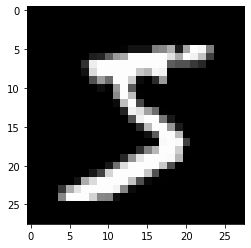

In [9]:
import matplotlib.pyplot as plt

image = x_train[0]
plt.imshow(image, cmap='gray')

Vidimo da je ovo 28 x 28 slika cifre 5. Ili, da li je ipak u pitanju 3? Odgovor možemo videti u `y_train` nizu koji definiše labele za slika iz `x_train`:

In [10]:
y_train[0]

5

## Priprema podataka za trening

Da bismo primenili klasičnu potpuno povezanu neuronsku mrežu, moramo primeniti određene transformacije ulaznog skupa podataka:
1. *Flatten*. CNN modeli će raditi sa 2D slikama (u našem slučaju 28 x 28). Međutim, za klasičnu (potpuno povezanu) neuronsku mrežu ćemo 2D slike poslagati u 1D niz koji prosleđujemo na ulaz neuronske mreže.
2. Normalizacija - namestićemo da se vrednosti piksela kreću u opsegu 0-1 umesto 0-255. Ovo ubrzava konvergenciju modela.
3. Enkodiranje labela da bi bile u odgovarajućem formatu za računanje funkcije gubitka.



### Flatten
<img src='https://drive.google.com/uc?id=1mDOGcuOT0FeoTYMC4rYefTBPH7ezb0XI' height=220>

Rezultat će biti niz od 28 x 28 = 784 elemenata:

In [11]:
x_train = x_train.reshape(60000, 784)
x_valid = x_valid.reshape(10000,784)

In [12]:
x_train.shape

(60000, 784)

In [13]:
x_train[0]

array([  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   3,  18,  18,  18,
       126, 136, 175,  26, 166, 255, 247, 127,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,  30,  36,  94, 154, 17

### Normalizacija

In [14]:
x_train = x_train / 255
x_valid = x_valid / 255 

Možemo videti da su vrednosti floating point između 0 i 1:

In [15]:
x_train.dtype

dtype('float64')

In [16]:
x_train.min()

0.0

In [17]:
x_train.max()

1.0

### Enkodiranje labela
Trenutno, labele su integeri između 0 i 9. U našoj postavci, ako je stvarna labela 7, želimo da kažemo da je jednako pogrešno da predvidimo 2 ili 4. Međutim, ako ostavimo da su labele integeri, 7-2 > 7-4 pa ispada kao da je manje pogrešno da predvidimo 4 nego da predvidimo 2. Ako bismo ostavili brojeve u numeričkom opsegu, model bi mogao da izvuče neke zaključke bazirano na tome koliko smo blizu numeričkoj kategoriji koju želimo, a to nije znanje koje mi želimo da ugradimo u model.

Zato ćemo primeniti *1-hot-encoding* transformaciju:

<img src='https://drive.google.com/uc?id=1yojDP7_Sq_i1WZ8LAosNImdZRGddhfPc' height=120>

Odnosno, transformisaćemo numeričke labele u vrednosti koje omogućavaju modelu da ih razume kao kategoričke vrednosti.

U primeru sa Red, Green, Blue:

```python
values = ['red, green, blue, green']
```

bismo konvertovali u 

```python
values = [
    [1, 0, 0],
    [0, 0, 1],
    [0, 1, 0],
    [0, 0, 1]
]
```

Da bismo ovo postigli u našem MNIST primeru, koristimo [to_categorical](https://www.tensorflow.org/api_docs/python/tf/keras/utils/to_categorical) funkciju (radimo isto i za trening i za validacione primere):


 

Prve tri labele pre transformacije:

In [18]:
y_train[0:3]

array([5, 0, 4], dtype=uint8)

In [19]:
import tensorflow.keras as keras
num_categories = 10

y_train = keras.utils.to_categorical(y_train, num_categories)
y_valid = keras.utils.to_categorical(y_valid, num_categories)

Prve 3 vrednosti trening labela nakon transformacije:

In [20]:
y_train[0:3]

array([[0., 0., 0., 0., 0., 1., 0., 0., 0., 0.],
       [1., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 1., 0., 0., 0., 0., 0.]], dtype=float32)

# Model
Proći ćemo kroz sledeće korake:
1. Kreiranje modela
2. (opciono) Sumarizacija modela
3. Kompajliranje modela
4. Treniranje modela

## Kreiranje modela

Kreiraćemo jednostavnu [potpuno povezanu neuronsku mrežu](https://developers.google.com/machine-learning/glossary#hidden-layer) sa više skrivenih slojeva:
1. Ulazni sloj (prima podatke specificirane u određenoj formi - u našem primeru, niz od 28*28=784 elemenata)
2. Više skrivenih
3. Izlazni sloj koji vraća predikciju mreže za prosleđeni ulaz (sliku transformisanu u niz of 784 vrednosti piksela).

Za potpuno povezanu mrežu možemo koristiti Keras-ov [`Sequential`](https://www.tensorflow.org/api_docs/python/tf/keras/Sequential) model da inicijalizujemo instancu modela koji će imati niz slojeva kroz koje će podaci prolaziti sekvencijalno:

In [21]:
from tensorflow.keras.models import Sequential

model = Sequential()

Ulazni sloj je potpuno povezan (*densely connected*) - svaki neuron ulaza utiče na svaki neuron narednog (1. skrivenog) sloja. Koristimo Kerasov-u [ `Dense`](https://www.tensorflow.org/api_docs/python/tf/keras/layers/Dense) klasu: 
* Argument `units` definiše broj neurona u prvom skrivenom sloju. U prvom skrivenom sloju ćemo koristiti 512 neurona (eksperimentalno određeno). 
* Argument `activation` definiše aktivacionu funkciju (koristićemo ReLu).
* Argument `input_shape`specificira `shape` ulaznih podataka (u ovom primeru 1D niz od 784 vrednosti).



In [22]:
from tensorflow.keras.layers import Dense

model.add(Dense(units=512, activation='relu', input_shape=(784,)))

Dodajemo još jedan skriveni sloj od 512 neurona:

In [23]:
model.add(Dense(units = 512, activation='relu'))

Kreiramo izlazni sloj:
*   Ovaj sloj koristi *SoftMax* aktivacionu funkciju
*   Pošto cifre razvrstavamo u 10 kategorija, ovaj sloj ima 10 neurona - vrednost pojedinačnog neurona je verovatnoća koju model pripisuje odgovajućoj klasi.



In [24]:
model.add(Dense(units = 10, activation='softmax'))

## Sumarizacija modela
Keras obezbeđuje instancu [`summary`](https://www.tensorflow.org/api_docs/python/tf/summary) metode koja ispisuje sumarizaciju kreiranog modela. Obratite pažnju da nam ispisuje i broj podesivih (*trainable*) parametara.

In [25]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 512)               401920    
                                                                 
 dense_1 (Dense)             (None, 512)               262656    
                                                                 
 dense_2 (Dense)             (None, 10)                5130      
                                                                 
Total params: 669,706
Trainable params: 669,706
Non-trainable params: 0
_________________________________________________________________


## Kompajliranje modela

Konačno, model moramo [kompajlirati](https://www.tensorflow.org/api_docs/python/tf/keras/Sequential#compile). U ovom koraku specificiramo funkciju gubitka (za naš slučaj, `categorical_crossentropy`). Takođe specificiramo da želimo da posmatramo metriku tačnosti (`accuracy`) dok se model trenira:

In [26]:
model.compile(loss='categorical_crossentropy', metrics=['accuracy'])

## Treniranje modela

Koristimo [`fit`](https://www.tensorflow.org/api_docs/python/tf/keras/Model#fit) metodu koja očekuje sledeće argumente:
* trening podatke
* labele trening podataka
* broj iteracija kroz ceo trening skup (broj epoha)
* validacione podatke i njihove labele.



In [27]:
history = model.fit(
    x_train, y_train, epochs=5, verbose=1, validation_data=(x_valid, y_valid)
)

Epoch 1/5
1875/1875 [==============================] - 23s 12ms/step - loss: 0.1933 - accuracy: 0.9431 - val_loss: 0.1075 - val_accuracy: 0.9688
Epoch 2/5
1875/1875 [==============================] - 22s 12ms/step - loss: 0.1011 - accuracy: 0.9744 - val_loss: 0.1052 - val_accuracy: 0.9756
Epoch 3/5
1875/1875 [==============================] - 22s 11ms/step - loss: 0.0858 - accuracy: 0.9801 - val_loss: 0.1109 - val_accuracy: 0.9776
Epoch 4/5
1875/1875 [==============================] - 22s 12ms/step - loss: 0.0724 - accuracy: 0.9831 - val_loss: 0.1479 - val_accuracy: 0.9778
Epoch 5/5
1875/1875 [==============================] - 30s 16ms/step - loss: 0.0681 - accuracy: 0.9853 - val_loss: 0.1513 - val_accuracy: 0.9785


## Analiza rezultata treniranja
Za svaku od 5 epoha, posmatrajte kako se kreću `accuracy` i `val_accuracy` vrednosti:
* `accuracy` - tačnost modela u datoj epohi merena na **trening** skupu
* `val_accuracy` - tačnost modela u datoj epohi merena na **validacionom** skupu (koji nije korišćen za trening modela).

U datom primeru, možemo videti da model brzo postiže tačnost blisku 100% i na trening i na validacionom skupu. Sledeći korak bi bio da primenimo ovaj model na novim podacima koje model nije video ([*inference*](https://blogs.nvidia.com/blog/2016/08/22/difference-deep-learning-training-inference-ai/))